# Review the saved 4,000-update NN comparison

**Run All here only loads saved data, restores final models, and plots histories. It does not train anything or overwrite the experiment.**

The selected export is the approximately 256-minute comparison with GLAd periods 1, 50, 100 and 200. It contains the complete scalar histories, per-update GLAd diagnostics, final model weights, initial weights, train/test data and experiment metadata. Plots do not require rerunning optimization.

The export is not a complete general-purpose optimizer checkpoint: Adam moments/scheduler state and cached GLAd Hessians are absent. These particular GLAd runs end at update 4,000, a refresh boundary for every selected period, so their next step can be reconstructed from the saved final weights and Lambda. No continuation is performed here.

Paper relationship: Section 5.1 / Appendix E.1 of the local 2026-10-22 manuscript; public reference [arXiv:2602.08069v1](https://arxiv.org/abs/2602.08069v1). This is the saved corrected finite-power experiment with its own recorded settings, not a reproduction of the historical paper plots. The audit and a source snapshot are under `corrected_results/diagnostics/long_run_20261106_new/`.


In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import pickle
from pathlib import Path
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

torch.set_num_threads(1)
NN_DIR = Path.cwd() if (Path.cwd() / "GLAdSSNOptimizer_new.py").exists() else Path.cwd() / "NN"
RUN_FILE = NN_DIR / "corrected_results/20261106_023855_023509/nn_results_new.pkl"
with RUN_FILE.open("rb") as stream:
    saved = pickle.load(stream)
metadata = saved["metadata"]
plot_histories = saved["histories"]
all_run_info = saved["statuses"]
X, Y = saved["training_inputs"], saved["training_targets"]
initial_state = saved["initial_state"]
simulated_test_dataset = saved["test_dataset"]
all_histories = {
    label: tuple(history[key] for key in ("loss", "time", "grad_norm", "hessian_norm") + (("Lambda",) if "Lambda" in history else ()))
    for label, history in plot_histories.items()
}
print("Loaded:", RUN_FILE.resolve())
print("Saved methods:", list(plot_histories))
print("Objective:", metadata["objective"], "K:", metadata["K"], "epsilon:", metadata["normalization_eps"])
print("No optimization has been run.")

Loaded: C:\Users\cleme\Desktop\Github Repos\skip-the-hessian-keep-the-rates\NN\corrected_results\20261106_023855_023509\nn_results_new.pkl
Saved methods: ['Adam', 'GLAd-SSN', 'GLAd-SSN m=50', 'GLAd-SSN m=100', 'GLAd-SSN m=200']
Objective: finite_power_surrogate K: 5 epsilon: 1e-07
No optimization has been run.


In [2]:
class Net(nn.Module):
    def __init__(self, dtype=X.dtype):
        super().__init__()
        self.fc1 = nn.Linear(2, 16, dtype=dtype)
        self.fc2 = nn.Linear(16, 16, dtype=dtype)
        self.fc3 = nn.Linear(16, 1, dtype=dtype)

    def forward(self, x):
        return self.fc3(torch.tanh(self.fc2(torch.tanh(self.fc1(x)))))

all_models = {}
for label, state in saved["final_model_states"].items():
    model = Net()
    model.load_state_dict(state)
    all_models[label] = model.eval()

rows = ["| Method | Updates | Runtime (min) | Final objective | Final gradient norm |",
        "| :--- | ---: | ---: | ---: | ---: |"]
for label, h in plot_histories.items():
    rows.append(f"| {label} | {len(h['loss'])-1} | {h['time'][-1]/60:.2f} | {h['loss'][-1]:.6g} | {h['grad_norm'][-1]:.6g} |")
display(Markdown("\n".join(rows)))
print("Final trained models are available in all_models.")

| Method | Updates | Runtime (min) | Final objective | Final gradient norm |
| :--- | ---: | ---: | ---: | ---: |
| Adam | 15000 | 3.33 | 0.342029 | 0.487899 |
| GLAd-SSN | 4000 | 238.04 | 0.00169211 | 0.000122346 |
| GLAd-SSN m=50 | 4000 | 6.66 | 0.0147312 | 0.00943401 |
| GLAd-SSN m=100 | 4000 | 4.77 | 0.0149753 | 0.010629 |
| GLAd-SSN m=200 | 4000 | 3.54 | 0.0156524 | 0.00900247 |

Final trained models are available in all_models.


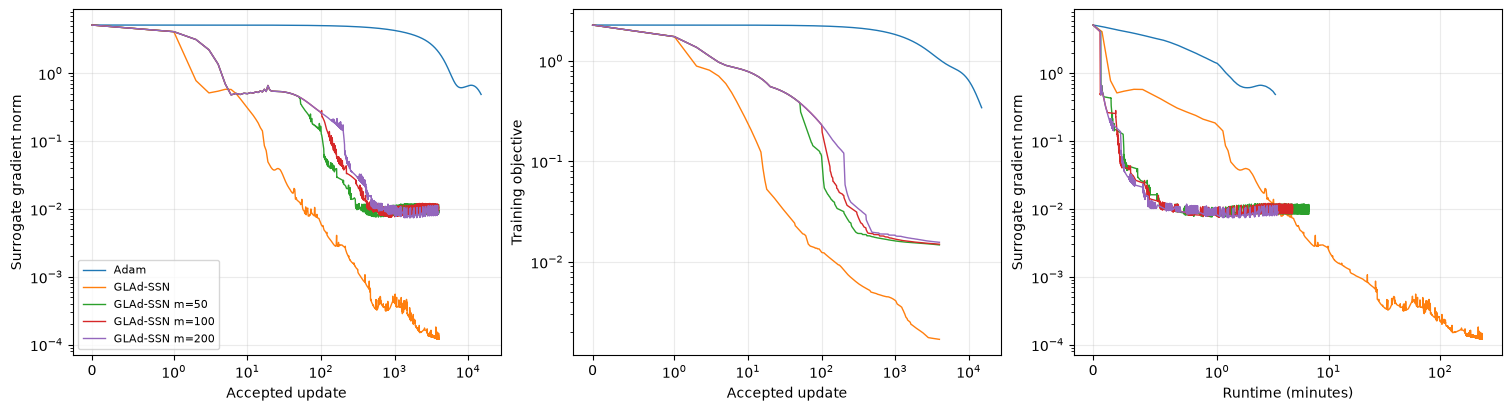

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
for label, h in plot_histories.items():
    axes[0].semilogy(h["grad_norm"], label=label, lw=1)
    axes[1].semilogy(h["loss"], label=label, lw=1)
    axes[2].semilogy([t/60 for t in h["time"]], h["grad_norm"], label=label, lw=1)
axes[0].set(xlabel="Accepted update", ylabel="Surrogate gradient norm")
axes[1].set(xlabel="Accepted update", ylabel="Training objective")
axes[2].set(xlabel="Runtime (minutes)", ylabel="Surrogate gradient norm")
for ax in axes:
    ax.grid(True, alpha=.25)
    ax.set_xscale("symlog", linthresh=1)
axes[0].legend(fontsize=8)
plt.show()

The original exported figures remain beside the pickle file. The separately saved diagnostic image `corrected_results/diagnostics/long_run_20261106_new/saved_run_diagnostics_new.png` adds accepted damping and linear iteration axes.

To inspect or evaluate a trained model, use e.g. `all_models["GLAd-SSN m=50"]`. Its weights are restored from the saved result. Re-running the **original experiment's training cells** starts those methods again from the initial weights; this review notebook avoids that.
